# IQR - Proximity rule _ this works on the basis of boxplot,

<div>
   <img src ="https://media.geeksforgeeks.org/wp-content/uploads/20211010215044/UntitledDiagram21.jpg" width="500" height="600"> 
</div>

this Technique works best on skewed feature column-

<div>
   <img src ="https://www.biologyforlife.com/uploads/2/2/3/9/22392738/c101b0da6ea1a0dab31f80d9963b0368_orig.png" width="500" height="600"> 
</div>


In [1]:
# dependencies

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement.csv')
df.shape


(1000, 3)

In [3]:
df.sample(5)

,cgpa,placement_exam_marks,placed
607,7.76,49.0,1
26,7.45,8.0,1
298,6.16,48.0,0
523,6.13,19.0,0
527,7.72,37.0,0


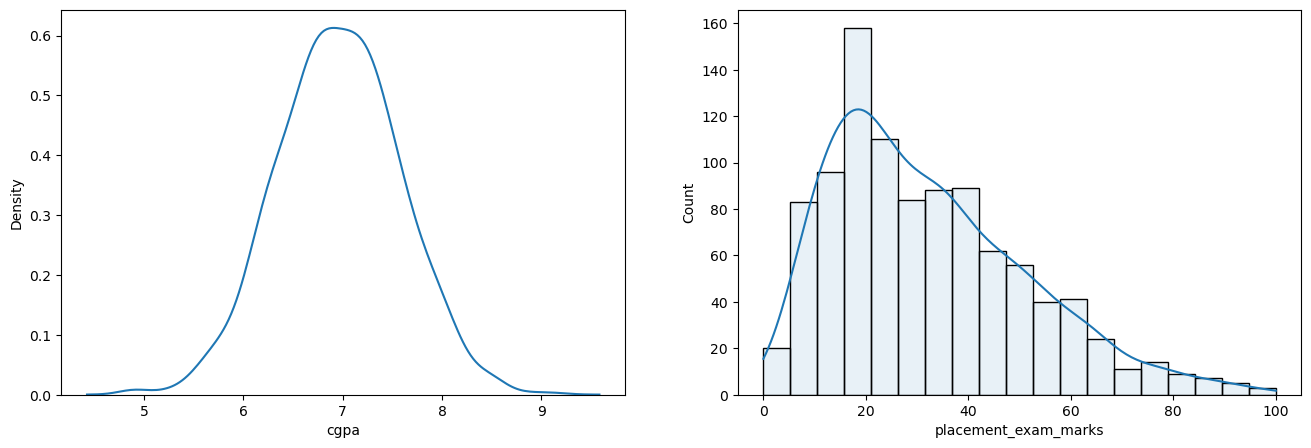

In [14]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.his(df['cgpa'])

plt.subplot(1,2,2)
sns.histplot(df['placement_exam_marks'], kde=True, alpha=0.1)

plt.show()

as we can see placement_exam_marks feature is skewed , needs iqr treatment

In [15]:
# or the best method that i like for checking skewness

df.skew()

cgpa                   -0.014530
placement_exam_marks    0.835642
placed                  0.044077
dtype: float64

In [16]:
# as we can see , cgpa is 0.01 -- pretty close to normal distribution
# but placement_exam_marks is 0.8 -- this is very skewed 

<Axes: xlabel='placement_exam_marks'>

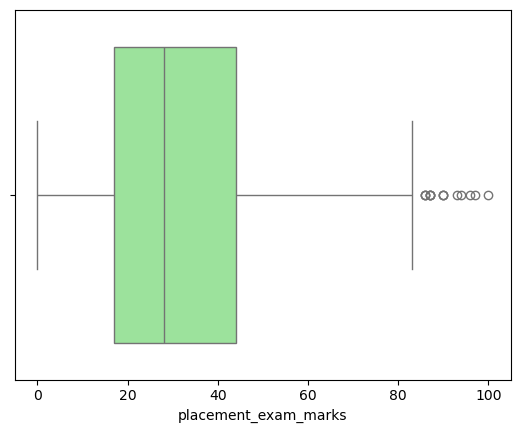

In [20]:
sns.boxplot(df['placement_exam_marks'],color='lightgreen',orient='h')


as we can see some outliers are detected at 90-100 on x axis - this shows that data is skewed at that end - so data is right skewed


now we need to fetch outliers - then either capping or trimming

In [21]:
percentile25 = df['placement_exam_marks'].quantile(0.25)
percentile75 = df['placement_exam_marks'].quantile(0.75)

In [22]:
percentile25

17.0

In [23]:
percentile75

44.0

In [24]:
iqr = percentile75 - percentile25

In [25]:
iqr

27.0

In [29]:
v_max = percentile75 + (1.5*iqr) 
v_min = percentile25 - (1.5 * iqr)

In [30]:
v_max

84.5

In [31]:
v_min

-23.5

## finding outliers

In [32]:
df[df['placement_exam_marks'] > v_max]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


Obviously there wont be any outlier at lower limit - since min marks is 0 and we have v_min = -23

## timming

In [33]:
timmed_df = df[df['placement_exam_marks'] < v_max]

In [34]:
timmed_df.shape

(985, 3)

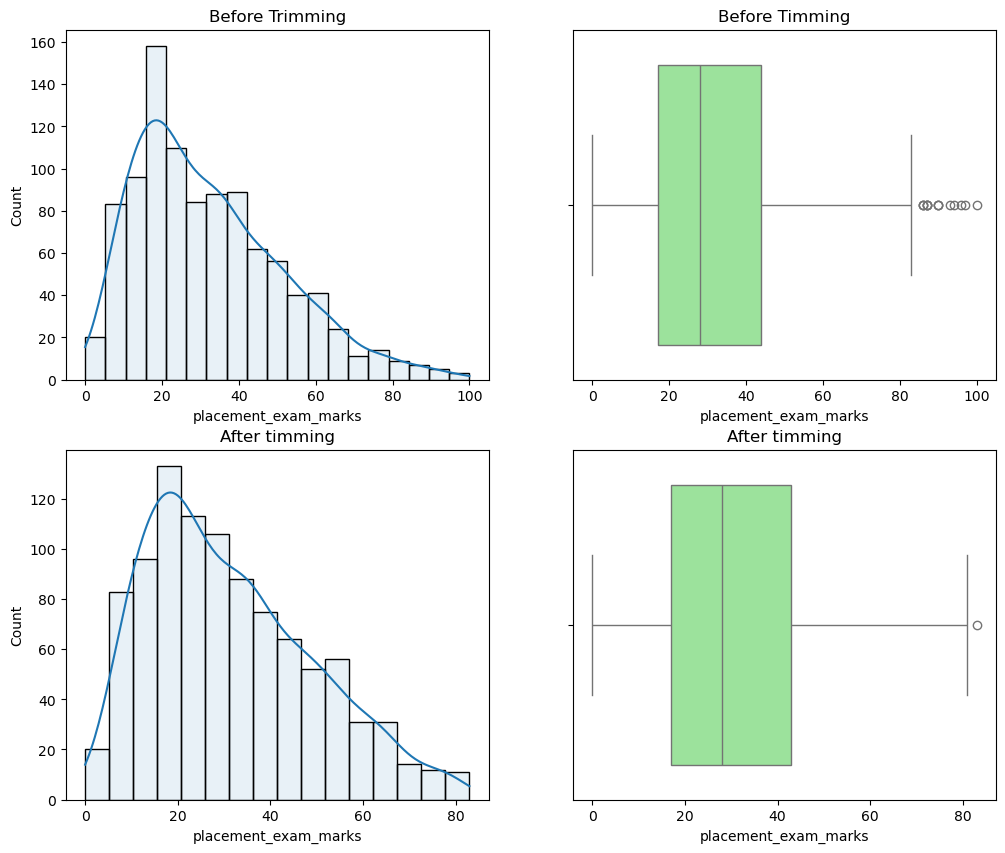

In [46]:
# compare 

plt.figure(figsize=(12,10))

plt.subplot(2,2,1)
plt.title('Before Trimming')
sns.histplot(df['placement_exam_marks'], kde=True, alpha=0.1)

plt.subplot(2,2,2)
plt.title('Before Timming')
sns.boxplot(df['placement_exam_marks'],color='lightgreen',orient='h')

plt.subplot(2,2,3)
plt.title('After timming')
sns.histplot(timmed_df['placement_exam_marks'], kde=True, alpha=0.1)

plt.subplot(2,2,4)
plt.title('After timming')
sns.boxplot(timmed_df['placement_exam_marks'],color='lightgreen',orient='h')

plt.show()

## Capping

In [52]:
capped_df = df.copy()

In [53]:
capped_df['placement_exam_marks'] = np.where(df['placement_exam_marks'] > v_max ,
                     v_max,
                     np.where(
                     df['placement_exam_marks'] < v_min,
                     v_min,
                     df['placement_exam_marks']))

In [56]:
capped_df.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961240,32.136500,0.489000
std,0.615898,18.865419,0.500129
min,4.890000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,9.120000,84.500000,1.000000


as we can see = max	9.120000	84.500000 , --> successful 

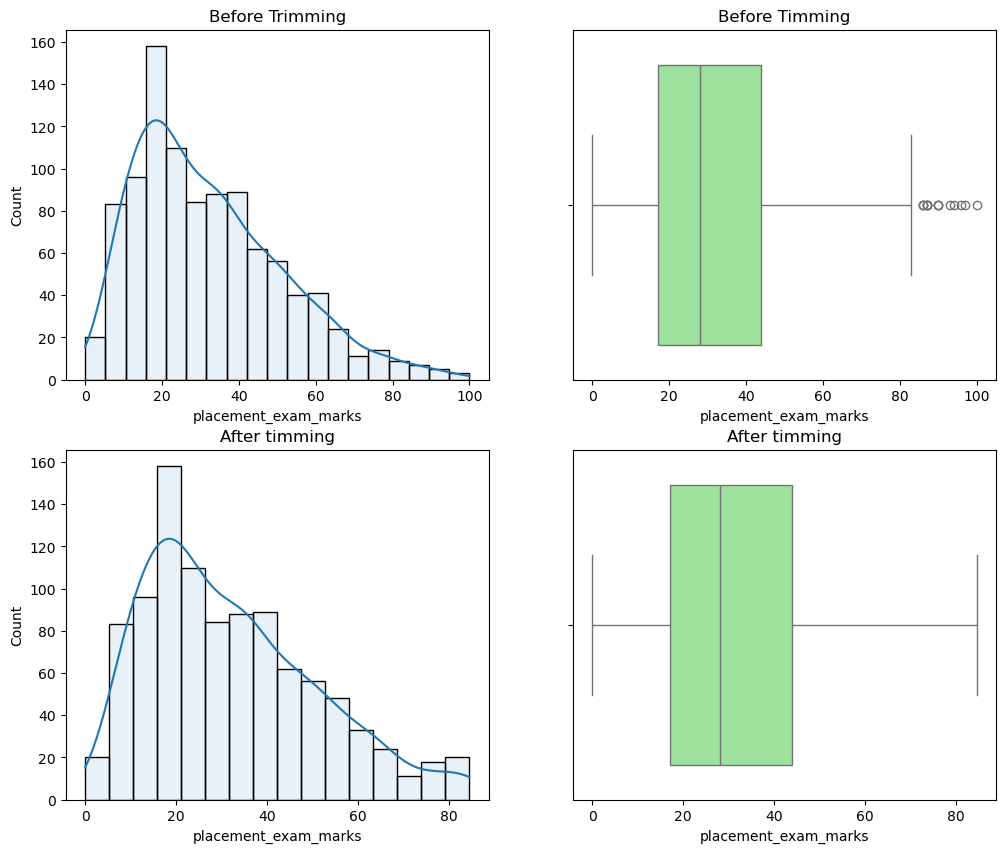

In [57]:
# compare 

plt.figure(figsize=(12,10))

plt.subplot(2,2,1)
plt.title('Before Trimming')
sns.histplot(df['placement_exam_marks'], kde=True, alpha=0.1)

plt.subplot(2,2,2)
plt.title('Before Timming')
sns.boxplot(df['placement_exam_marks'],color='lightgreen',orient='h')

plt.subplot(2,2,3)
plt.title('After timming')
sns.histplot(capped_df['placement_exam_marks'], kde=True, alpha=0.1)

plt.subplot(2,2,4)
plt.title('After timming')
sns.boxplot(capped_df['placement_exam_marks'],color='lightgreen',orient='h')

plt.show()

✅
